In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("..")
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from src.config import cfg

In [ ]:
from src.data_loader import load_raw
from src.cleaning import clean
from src.features import build_features, encode_features

clean_df = clean(load_raw())
                            
featured = build_features(clean_df)
print("Engineered shape:", featured.shape)

display(featured[[cfg.DATETIME_COL, cfg.TARGET_COL, "Hour", "DayOfWeek",
                  "Month", "Year", "IsWeekend",
                  "lag24", "lag168", "roll_24"]].head(3))
display(featured[["Hour", "DayOfWeek", "Month", "Year",
                  "IsWeekend", "lag24", "lag168", "roll_24"]].describe().T)

X, y = encode_features(featured)
print("Encoded feature matrix:", X.shape)
display(X.iloc[:, :12].head(3))

2026-11-24 14:08:32,678 | INFO | src.data_loader | data loaded
2026-11-24 14:08:32,713 | INFO | src.cleaning | Dropped rows with invalid dates or missing target
2026-11-24 14:08:32,735 | INFO | src.cleaning | Dropped exact duplicate rows
2026-11-24 14:08:32,742 | INFO | src.cleaning | Sorted data chronologically
2026-11-24 14:08:32,759 | INFO | src.cleaning | Reindexed to complete hourly range
2026-11-24 14:08:32,763 | INFO | src.cleaning | Interpolated missing target values
2026-11-24 14:08:32,764 | INFO | src.cleaning | Cleaning completed | Rows: 145392 | Datetime type: datetime64[us] | Target type: float64


Engineered shape: (145224, 10)


,Datetime,PJME_MW,Hour,DayOfWeek,Month,Year,IsWeekend,lag24,lag168,roll_24
0,2002-01-08 01:00:00,29445.0,1,1,1,2002,0,26862.0,30393.0,33452.583333
1,2002-01-08 02:00:00,28670.0,2,1,1,2002,0,25976.0,29265.0,33560.208333
2,2002-01-08 03:00:00,28375.0,3,1,1,2002,0,25641.0,28357.0,33672.458333


,count,mean,std,min,25%,50%,75%,max
Hour,145224.0,11.500000,6.922210,0.000000,5.7500,11.500000,17.250000,23.000000
DayOfWeek,145224.0,2.999525,1.999712,0.000000,1.0000,3.000000,5.000000,6.000000
Month,145224.0,6.442124,3.435979,1.000000,3.0000,6.000000,9.000000,12.000000
Year,145224.0,2009.809728,4.787155,2002.000000,2006.0000,2010.000000,2014.000000,2018.000000
IsWeekend,145224.0,0.285573,0.451688,0.000000,0.0000,0.000000,1.000000,1.000000
lag24,145224.0,32077.417762,6465.766686,14544.000000,27568.0000,31419.000000,35646.000000,62009.000000
lag168,145224.0,32074.533534,6462.685157,14544.000000,27569.0000,31418.000000,35639.000000,62009.000000
roll_24,145224.0,32077.859147,4686.916723,19307.416667,28604.1875,31324.291667,34974.635417,52261.416667


Encoded feature matrix: (145224, 48)


,Year,IsWeekend,lag24,lag168,roll_24,Hour_0,Hour_1,Hour_2,Hour_3,Hour_4,Hour_5,Hour_6
Datetime,,,,,,,,,,,,
2002-01-08 01:00:00,2002,0,26862.0,30393.0,33452.583333,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2002-01-08 02:00:00,2002,0,25976.0,29265.0,33560.208333,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2002-01-08 03:00:00,2002,0,25641.0,28357.0,33672.458333,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## Data preparation and chronological 80/20 split

In [3]:
from src.model import chronological_split

X_train, X_test, y_train, y_test, split_at = chronological_split(X, y, cfg.SPLIT_RATIO)
assert X_train.index.max() < X_test.index.min()

split_info = {
    "train_rows": len(X_train), "test_rows": len(X_test),
    "train_period": [str(X_train.index.min()), str(X_train.index.max())],
    "test_period": [str(X_test.index.min()), str(X_test.index.max())],
    "split_timestamp": str(split_at),
}
display(pd.Series(split_info, name="value").to_frame())
print(f"Train {len(X_train)/len(X):.1%} / Test {len(X_test)/len(X):.1%}")

,value
train_rows,116179
test_rows,29045
train_period,"[2002-01-08 01:00:00, 2015-04-10 19:00:00]"
test_period,"[2015-04-10 20:00:00, 2018-08-03 00:00:00]"
split_timestamp,2015-04-10 20:00:00


Train 80.0% / Test 20.0%


## Training and evaluation

Linear regression vs. the reference approach `lag24` (same hour yesterday). Metrics: MAE, RMSE, R², MAPE.

In [4]:
from src.model import train_model, evaluate

model = train_model(X_train, y_train)
evaluation = evaluate(model, X_test, y_test)

summary = pd.DataFrame({
    "Linear regression": evaluation["model_metrics"],
    "Baseline lag24": evaluation["baseline_metrics"],
})
summary.loc["error_reduction_%"] = {
    metric: evaluation["improvement_pct"].get(metric, np.nan) for metric in summary.columns
}
display(summary)
print("R² gain vs baseline: %.4f points" % evaluation["r2_gain_points"])
print("First 10 learned coefficients:")
display(pd.Series(model.coef_, index=X.columns).sort_values(key=abs, ascending=False).head(10).to_frame("coefficient"))

,Linear regression,Baseline lag24
MAE,1675.925524,2184.268067
RMSE,2240.304005,3009.016267
R2,0.880879,0.785106
MAPE,5.295422,6.931436
error_reduction_%,NaN,NaN


R² gain vs baseline: 0.0958 points
First 10 learned coefficients:


,coefficient
Hour_4,-3032.273580
Hour_3,-2913.906208
Hour_5,-2883.575335
Hour_2,-2614.536326
Hour_6,-2241.550482
DayOfWeek_0,2081.500641
Hour_1,-2073.144322
Hour_19,1937.486245
Hour_18,1927.288037
Hour_20,1804.714680


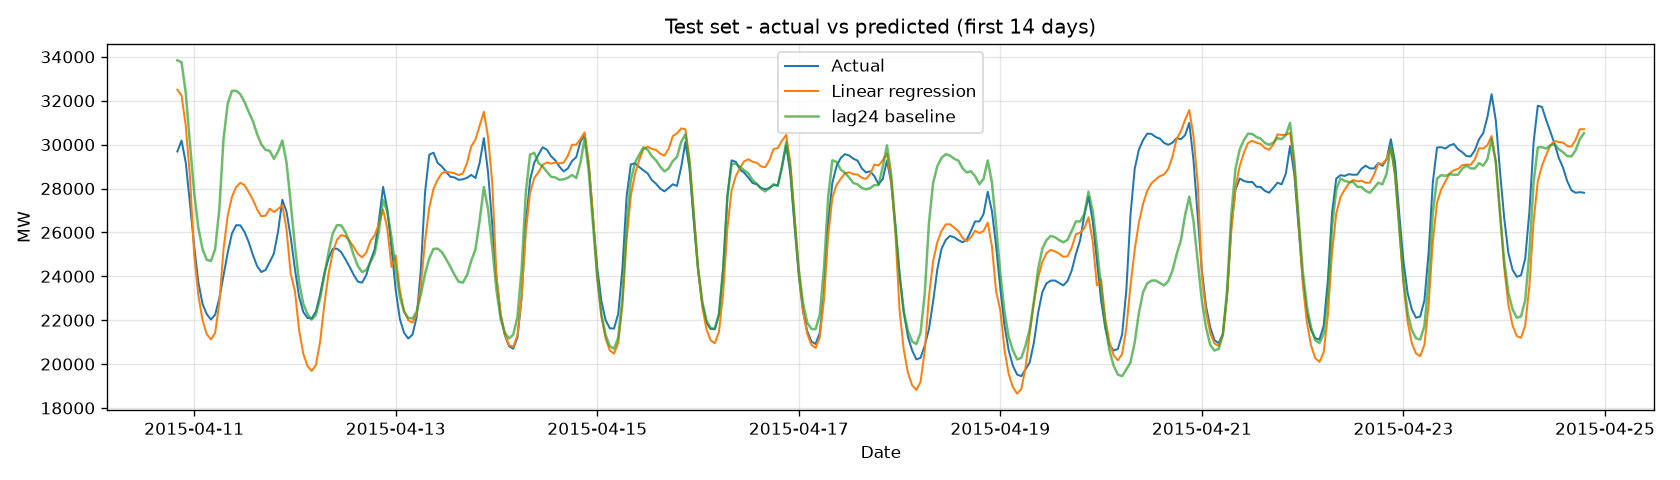

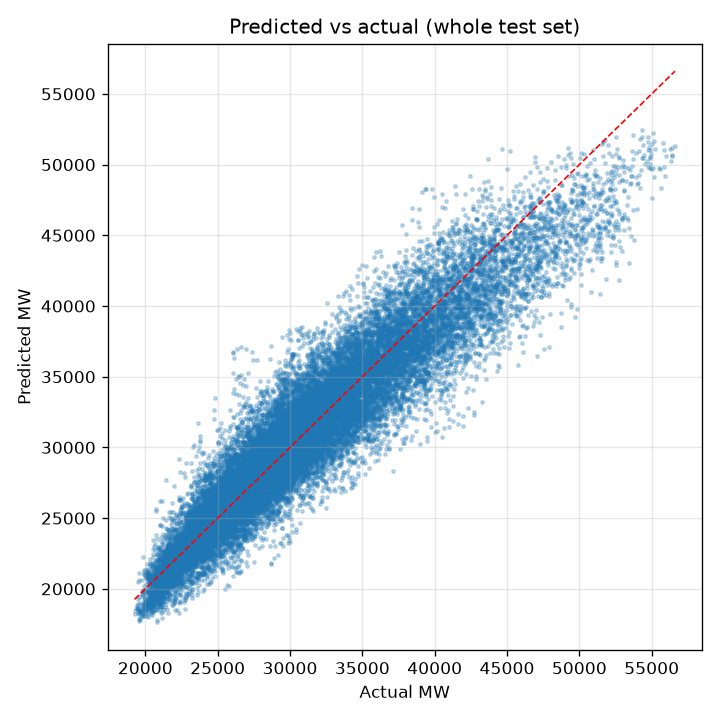

In [6]:
from src.model import plot_predictions, plot_residuals
plots = plot_predictions(y_test, evaluation, cfg.FIGURES_DIR)
plot_residuals(y_test, evaluation, cfg.FIGURES_DIR)
from IPython.display import Image
display(Image(filename=str(plots["zoom"])))
display(Image(filename=str(plots["scatter"])))